<a href="https://colab.research.google.com/github/ahammedzihadkhan/Thesis-scrap-/blob/main/Thesis_Pipeline_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-Commerce Customer Segmentation via Extended RFM & Machine Learning
**Pre-Defense ML Pipeline + Model Evaluation & Benchmark**
Batch 62, Department of CSE, City University, Bangladesh

Run the cells top to bottom (Colab: *Runtime → Run all*). Sections:
1. Setup & data acquisition
2. Cleaning & hygiene
3. Extended RFM feature engineering
4. Model training (K-Means, k = 2..10)
5. **Model evaluation** (internal validity, stability, generalisation)
6. **Algorithm benchmark** (K-Means vs Ward vs GMM vs DBSCAN)
7. Segment profiling & visualisation
8. Marketing queue export

## 1. Setup & data acquisition

In [1]:
import os, glob, shutil, time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
SEED = 42
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "axes.edgecolor": "#333333", "figure.dpi": 110})
%matplotlib inline
print("Setup complete.")

Setup complete.


In [2]:
csv_path = "data/online_retail.csv"

if not os.path.exists(csv_path):
    # Option 1: Kaggle (works on Colab)
    try:
        try:
            import kagglehub
        except ImportError:
            os.system("pip install -q kagglehub")
            import kagglehub
        folder = kagglehub.dataset_download("carrie1/ecommerce-data")
        found = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
        shutil.copy(found[0], csv_path)
        print("Loaded via Kaggle.")
    except Exception as e:
        print(f"Kaggle failed ({e}). Trying UCI...")
        # Option 2: UCI repository
        try:
            os.system("pip install -q openpyxl")
            url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
            urllib.request.urlretrieve(url, "data/Online_Retail.xlsx")
            pd.read_excel("data/Online_Retail.xlsx").to_csv(csv_path, index=False, encoding="ISO-8859-1")
            print("Loaded via UCI.")
        except Exception as e2:
            # Option 3: manual upload (Colab)
            print(f"UCI failed ({e2}). Please upload online_retail.csv / Online Retail.xlsx manually.")
            from google.colab import files
            up = files.upload()
            name = list(up.keys())[0]
            if name.endswith(".xlsx"):
                pd.read_excel(name).to_csv(csv_path, index=False, encoding="ISO-8859-1")
            else:
                shutil.copy(name, csv_path)

df_raw = pd.read_csv(csv_path, encoding="ISO-8859-1")
print(df_raw.shape)
df_raw.head()

100%|██████████| 7.20M/7.20M [00:00<00:00, 9.50MB/s]

Extracting files...


Loaded via Kaggle.
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 2. Cleaning & data hygiene

In [3]:
total_raw_rows = len(df_raw)
missing_cid_rows = int(df_raw["CustomerID"].isna().sum())

df_clean = df_raw.dropna(subset=["CustomerID"]).copy()
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)
cancelled_rows = int(df_clean["InvoiceNo"].str.startswith("C").sum())
df_clean = df_clean[~df_clean["InvoiceNo"].str.startswith("C")]
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["UnitPrice"] > 0)]
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
duplicate_rows = before - len(df_clean)

df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

print(f"Raw transactions        : {total_raw_rows:,}")
print(f"Missing CustomerID      : {missing_cid_rows:,} ({missing_cid_rows/total_raw_rows*100:.1f}%)")
print(f"Cancelled invoices      : {cancelled_rows:,}")
print(f"Duplicate line items    : {duplicate_rows:,}")
print(f"Final clean rows        : {len(df_clean):,}")
print(f"Unique customers        : {df_clean['CustomerID'].nunique():,}")

Raw transactions        : 541,909
Missing CustomerID      : 135,080 (24.9%)
Cancelled invoices      : 8,905
Duplicate line items    : 5,192
Final clean rows        : 392,692
Unique customers        : 4,338


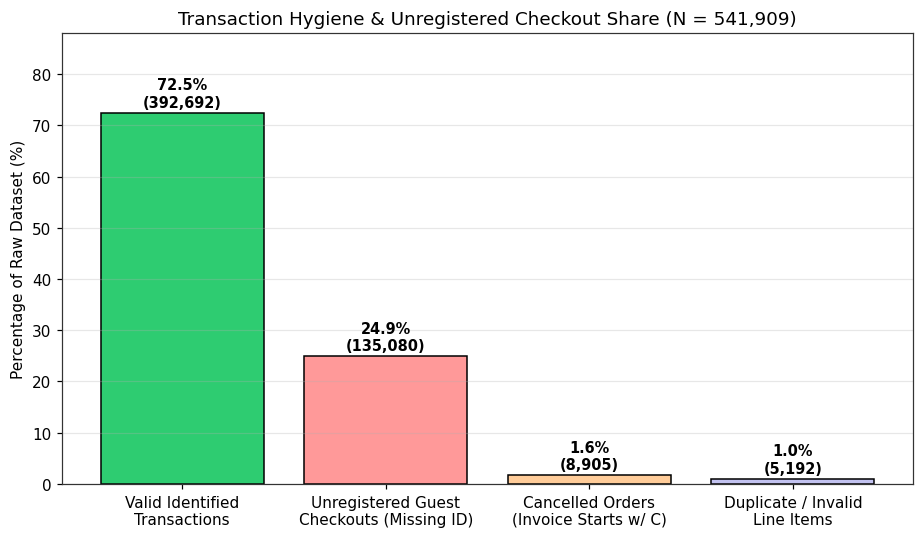

In [4]:
# transaction hygiene
cats = ["Valid Identified\nTransactions", "Unregistered Guest\nCheckouts (Missing ID)",
        "Cancelled Orders\n(Invoice Starts w/ C)", "Duplicate / Invalid\nLine Items"]
counts = [len(df_clean), missing_cid_rows, cancelled_rows, duplicate_rows]
pcts = [c / total_raw_rows * 100 for c in counts]
plt.figure(figsize=(8.5, 5))
bars = plt.bar(cats, pcts, color=["#2ecc71", "#ff9999", "#ffcc99", "#c2c2f0"], edgecolor="black")
for b, c, p in zip(bars, counts, pcts):
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f"{p:.1f}%\n({c:,})",
             ha="center", fontweight="bold", fontsize=9.5)
plt.ylim(0, 88); plt.ylabel("Percentage of Raw Dataset (%)")
plt.title(f"Transaction Hygiene & Unregistered Checkout Share (N = {total_raw_rows:,})")
plt.grid(axis="y", alpha=0.3); plt.tight_layout()
plt.savefig("outputs/fig4_1_account_vs_guest_tx.png", dpi=300); plt.show()

## 3. Extended RFM feature engineering (R, F, M, T, D)

In [5]:
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

def interpurchase_time(dates):
    days = np.sort(dates.dt.floor("D").unique())
    if len(days) <= 1:
        return 0.0
    return float(np.mean(np.diff(days) / np.timedelta64(1, "D")))

ext_rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
    InterPurchase_Time=("InvoiceDate", interpurchase_time),
    Basket_Depth=("StockCode", "nunique"),
    Country=("Country", "first"),
)
feature_cols = ["Recency", "Frequency", "Monetary", "InterPurchase_Time", "Basket_Depth"]

single = int((ext_rfm["Frequency"] == 1).sum())
repeat = int((ext_rfm["Frequency"] > 1).sum())
print(f"Customers (N)           : {len(ext_rfm):,}")
print(f"Single-invoice (F = 1)  : {single:,} ({single/len(ext_rfm)*100:.1f}%)")
print(f"Repeat regulars (F >= 2): {repeat:,} ({repeat/len(ext_rfm)*100:.1f}%)")
ext_rfm[feature_cols].describe().round(2)

Customers (N)           : 4,338
Single-invoice (F = 1)  : 1,493 (34.4%)
Repeat regulars (F >= 2): 2,845 (65.6%)


,Recency,Frequency,Monetary,InterPurchase_Time,Basket_Depth
count,4338.00,4338.00,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69,50.44,61.50
std,100.01,7.70,8985.23,65.24,85.37
min,1.00,1.00,3.75,0.00,1.00
25%,18.00,1.00,306.48,0.00,16.00
50%,51.00,2.00,668.57,31.00,35.00
75%,142.00,5.00,1660.60,73.00,77.00
max,374.00,209.00,280206.02,366.00,1787.00


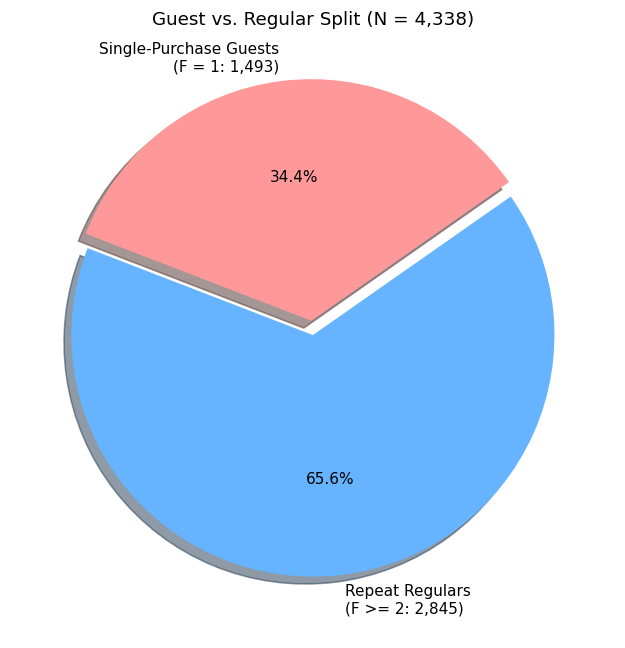

In [6]:
# Figure 4.2 - guest vs repeat
plt.figure(figsize=(6.5, 6))
plt.pie([single, repeat],
        labels=[f"Single-Purchase Guests\n(F = 1: {single:,})", f"Repeat Regulars\n(F >= 2: {repeat:,})"],
        autopct="%1.1f%%", startangle=35, explode=(0.06, 0), colors=["#ff9999", "#66b3ff"], shadow=True)
plt.title(f"Guest vs. Regular Split (N = {len(ext_rfm):,})")
plt.tight_layout(); plt.savefig("outputs/fig4_2_single_vs_repeat_pie.png", dpi=300); plt.show()

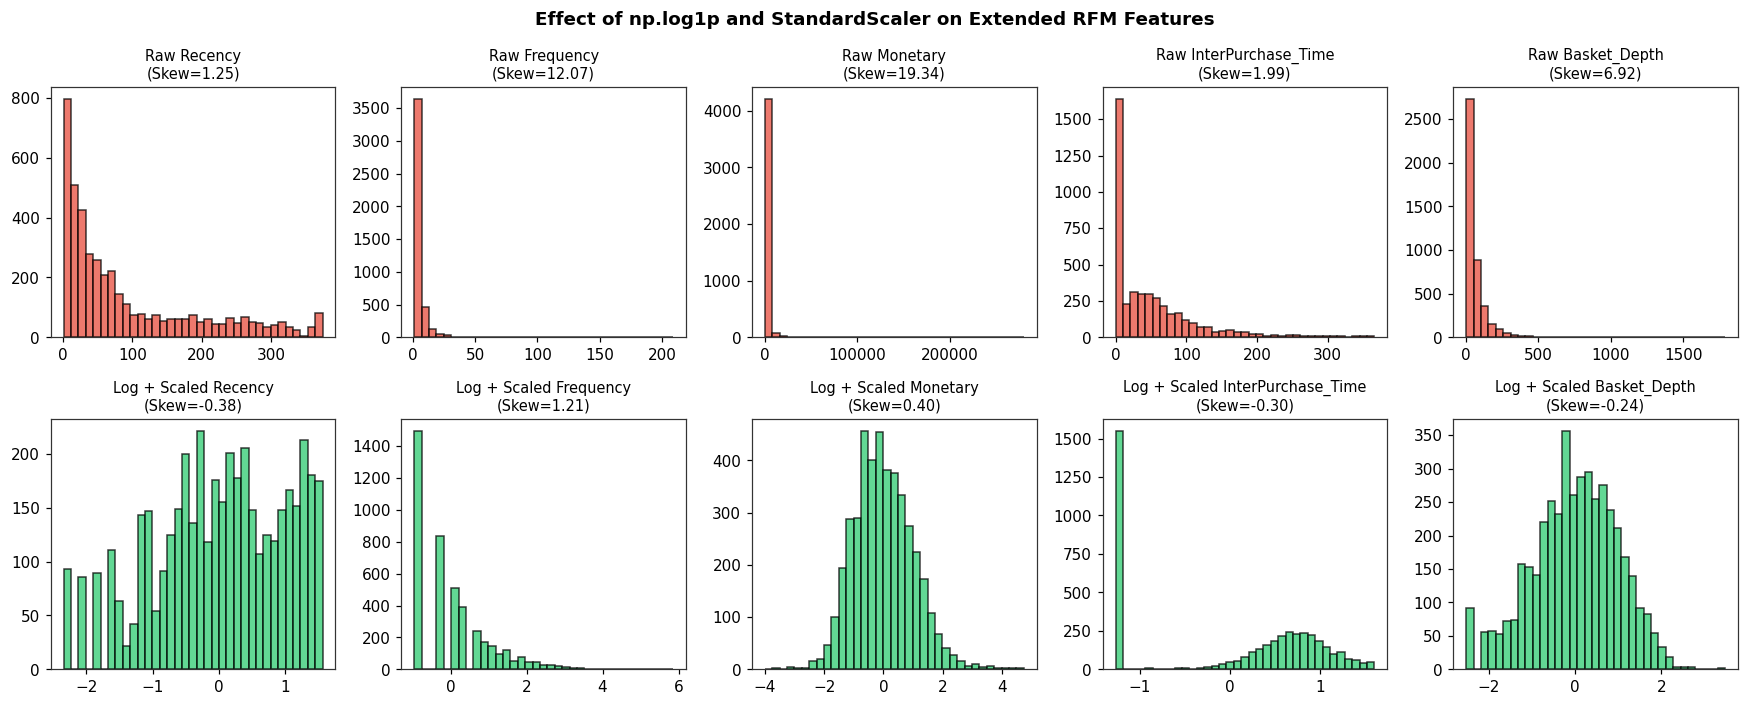

In [7]:
# Log transform + standardise
rfm_log = np.log1p(ext_rfm[feature_cols])
scaler = StandardScaler()
rfm_scaled = pd.DataFrame(scaler.fit_transform(rfm_log), index=ext_rfm.index, columns=feature_cols)
X = rfm_scaled.values

# Figure 4.3 - skewness correction
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for i, c in enumerate(feature_cols):
    axes[0, i].hist(ext_rfm[c], bins=35, color="#e74c3c", edgecolor="black", alpha=0.75)
    axes[0, i].set_title(f"Raw {c}\n(Skew={ext_rfm[c].skew():.2f})", fontsize=9.5)
    axes[1, i].hist(rfm_scaled[c], bins=35, color="#2ecc71", edgecolor="black", alpha=0.75)
    axes[1, i].set_title(f"Log + Scaled {c}\n(Skew={rfm_scaled[c].skew():.2f})", fontsize=9.5)
plt.suptitle("Effect of np.log1p and StandardScaler on Extended RFM Features", fontweight="bold")
plt.tight_layout(); plt.savefig("outputs/fig4_3_skewness_correction.png", dpi=300); plt.show()

## 4. Model training - K-Means sweep (k = 2..10)

In [8]:
records = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", random_state=SEED, n_init=10)
    lbl = km.fit_predict(X)
    records.append({"k": k, "WCSS": km.inertia_,
                    "Silhouette": silhouette_score(X, lbl),
                    "Davies-Bouldin": davies_bouldin_score(X, lbl),
                    "Calinski-Harabasz": calinski_harabasz_score(X, lbl)})
eval_df = pd.DataFrame(records)
eval_df.to_csv("outputs/table_4_1_kmeans_evaluation.csv", index=False)
eval_df.round(4)

,k,WCSS,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,11535.0939,0.4157,0.9440,3817.2054
1,3,8308.1169,0.3646,1.0613,3491.2121
2,4,7264.3566,0.3113,1.2442,2868.8358
3,5,6408.6958,0.2539,1.3338,2582.9897
4,6,5762.2484,0.2531,1.2821,2394.8661
5,7,5288.9430,0.2539,1.2104,2238.4147
6,8,4876.7994,0.2391,1.2083,2132.5885
7,9,4562.9882,0.2380,1.2521,2031.1590
8,10,4334.6206,0.2354,1.2378,1925.4345


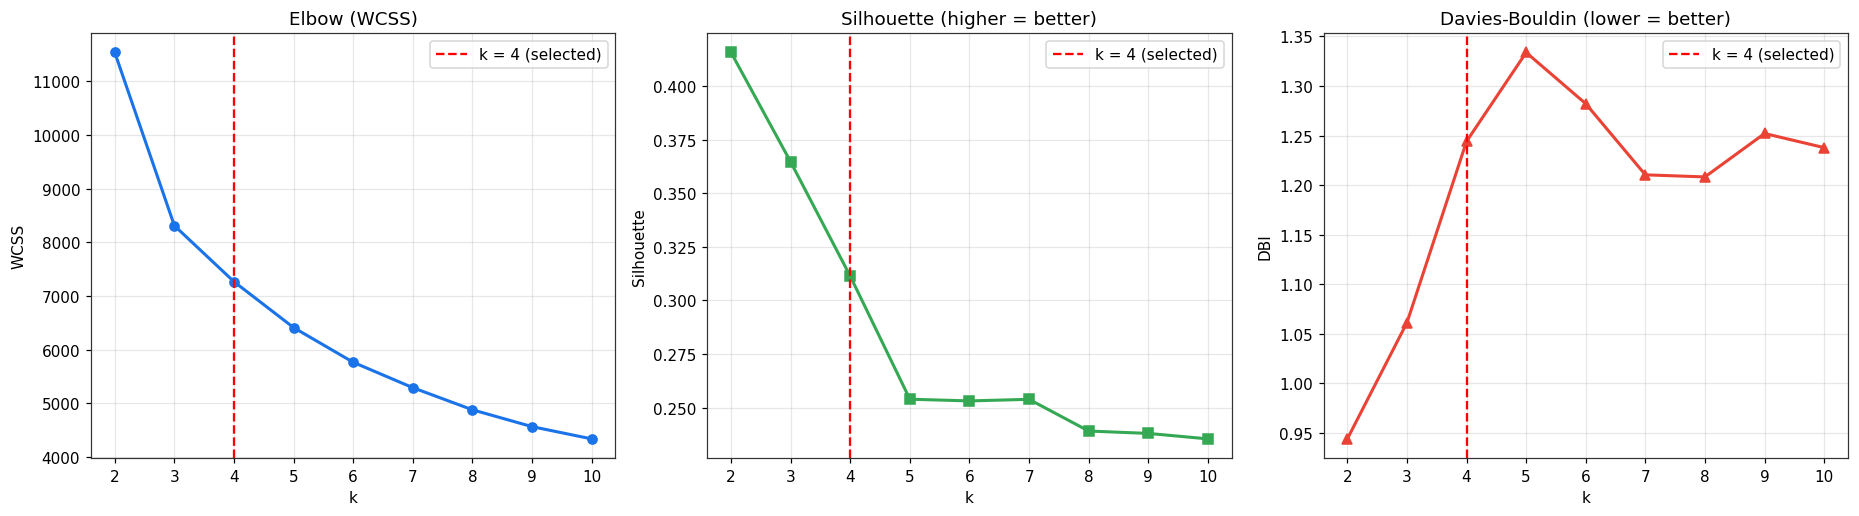

Highest silhouette at k = 2; selected k = 4 (silhouette 0.3113).


In [9]:
# Figure 4.4 - elbow + silhouette + DBI
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(eval_df.k, eval_df.WCSS, "o-", color="#1a73e8", lw=2)
ax[0].set(title="Elbow (WCSS)", xlabel="k", ylabel="WCSS")
ax[1].plot(eval_df.k, eval_df.Silhouette, "s-", color="#34a853", lw=2)
ax[1].set(title="Silhouette (higher = better)", xlabel="k", ylabel="Silhouette")
ax[2].plot(eval_df["k"], eval_df["Davies-Bouldin"], "^-", color="#ea4335", lw=2)
ax[2].set(title="Davies-Bouldin (lower = better)", xlabel="k", ylabel="DBI")
for a in ax:
    a.axvline(4, color="red", ls="--", label="k = 4 (selected)"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("outputs/fig4_4_elbow_silhouette.png", dpi=300); plt.show()

best_sil_k = int(eval_df.loc[eval_df.Silhouette.idxmax(), "k"])
print(f"Highest silhouette at k = {best_sil_k}; selected k = 4 "
      f"(silhouette {eval_df.loc[eval_df.k==4,'Silhouette'].iloc[0]:.4f}).")

## 5. Model evaluation
Three lenses: **(a)** internal validity per cluster, **(b)** stability under resampling, **(c)** generalisation to unseen customers.

         Size  Mean_Silhouette  Pct_Negative
Cluster                                     
0        1180           0.2222        0.9322
1        1572           0.4359        0.2545
2        1071           0.2508        0.3735
3         515           0.2607        5.2427

Overall silhouette: 0.3113 | samples with negative silhouette: 1.1%


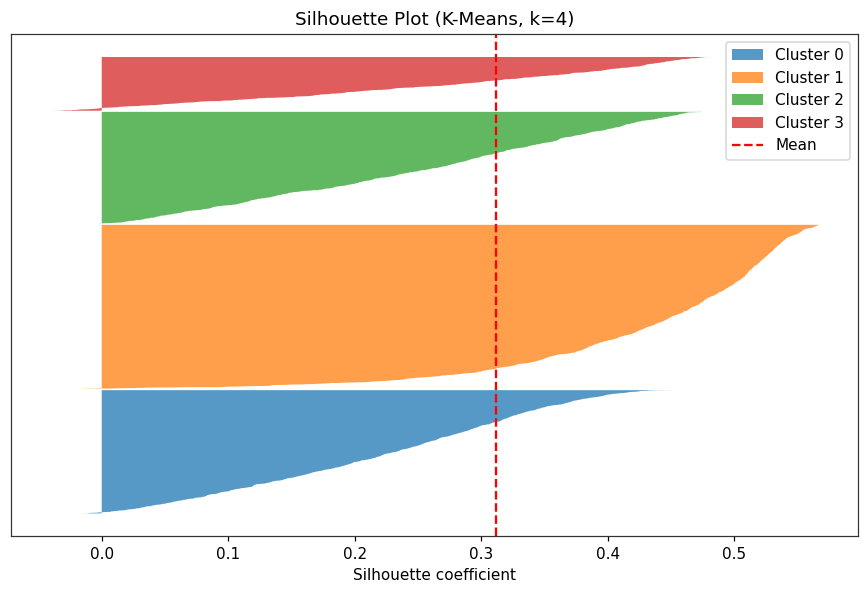

In [10]:
# (a) Per-cluster silhouette for the selected K-Means (k=4)
K = 4
km4 = KMeans(n_clusters=K, init="k-means++", random_state=SEED, n_init=10).fit(X)
labels4 = km4.labels_
sil_samples = silhouette_samples(X, labels4)

per_cluster = (pd.DataFrame({"Cluster": labels4, "Silhouette": sil_samples})
               .groupby("Cluster").agg(Size=("Silhouette", "size"),
                                       Mean_Silhouette=("Silhouette", "mean"),
                                       Pct_Negative=("Silhouette", lambda s: (s < 0).mean() * 100)).round(4))
print(per_cluster)
print(f"\nOverall silhouette: {sil_samples.mean():.4f} | samples with negative silhouette: {(sil_samples<0).mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 5.5))
y_lo = 10
for c in range(K):
    s = np.sort(sil_samples[labels4 == c]); y_hi = y_lo + len(s)
    ax.fill_betweenx(np.arange(y_lo, y_hi), 0, s, alpha=0.75, label=f"Cluster {c}")
    y_lo = y_hi + 10
ax.axvline(sil_samples.mean(), color="red", ls="--", label="Mean")
ax.set(title="Silhouette Plot (K-Means, k=4)", xlabel="Silhouette coefficient", yticks=[])
ax.legend(); plt.tight_layout(); plt.savefig("outputs/fig5_1_silhouette_plot.png", dpi=300); plt.show()

 k  Mean_ARI  Std_ARI  Min_ARI
 2    0.9826   0.0147   0.9499
 3    0.9770   0.0096   0.9625
 4    0.9371   0.0882   0.4802
 5    0.9011   0.0726   0.5905
 6    0.8561   0.0801   0.6131
 7    0.8027   0.1171   0.4927
 8    0.6941   0.1244   0.5273


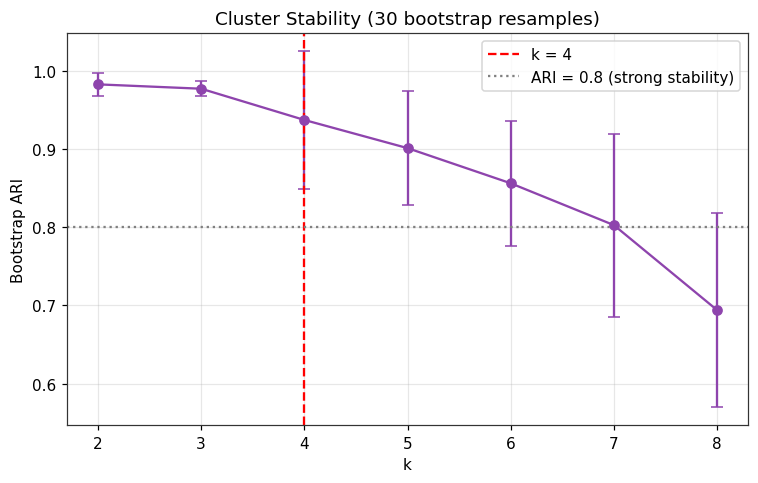

In [11]:
# (b) Stability: bootstrap Adjusted Rand Index vs. reference clustering, k = 2..8
rng = np.random.RandomState(SEED)
N_BOOT = 30
stab = []
for k in range(2, 9):
    ref = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    aris = []
    for b in range(N_BOOT):
        idx = rng.choice(len(X), size=len(X), replace=True)
        km_b = KMeans(n_clusters=k, n_init=5, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(ref.labels_, km_b.predict(X)))
    stab.append({"k": k, "Mean_ARI": np.mean(aris), "Std_ARI": np.std(aris), "Min_ARI": np.min(aris)})
stab_df = pd.DataFrame(stab)
stab_df.to_csv("outputs/table_5_1_stability.csv", index=False)
print(stab_df.round(4).to_string(index=False))

plt.figure(figsize=(7, 4.5))
plt.errorbar(stab_df.k, stab_df.Mean_ARI, yerr=stab_df.Std_ARI, fmt="o-", capsize=4, color="#8e44ad")
plt.axvline(4, color="red", ls="--", label="k = 4")
plt.axhline(0.8, color="gray", ls=":", label="ARI = 0.8 (strong stability)")
plt.xlabel("k"); plt.ylabel("Bootstrap ARI"); plt.title("Cluster Stability (30 bootstrap resamples)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("outputs/fig5_2_stability.png", dpi=300); plt.show()

In [12]:
# (c) Generalisation: fit on 80% of customers, score the unseen 20%
X_tr, X_te = train_test_split(X, test_size=0.2, random_state=SEED)
gen = []
for k in [2, 3, 4, 5, 6]:
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_tr)
    gen.append({"k": k,
                "Train_Silhouette": silhouette_score(X_tr, m.labels_),
                "Test_Silhouette": silhouette_score(X_te, m.predict(X_te)),
                "Test_DBI": davies_bouldin_score(X_te, m.predict(X_te))})
gen_df = pd.DataFrame(gen)
gen_df["Gap"] = gen_df.Train_Silhouette - gen_df.Test_Silhouette
gen_df.to_csv("outputs/table_5_2_generalisation.csv", index=False)
gen_df.round(4)

,k,Train_Silhouette,Test_Silhouette,Test_DBI,Gap
0,2,0.4197,0.4027,0.9656,0.0170
1,3,0.3630,0.3659,1.0487,-0.0028
2,4,0.3098,0.3139,1.2380,-0.0040
3,5,0.2541,0.2470,1.3614,0.0071
4,6,0.2525,0.2455,1.2814,0.0070


## 6. Algorithm benchmark

In [13]:
def timed(fn):
    t = time.perf_counter(); out = fn(); return out, time.perf_counter() - t

def score(X, lbl):
    mask = lbl != -1
    if len(set(lbl[mask])) < 2:
        return np.nan, np.nan, np.nan
    return (silhouette_score(X[mask], lbl[mask]),
            davies_bouldin_score(X[mask], lbl[mask]),
            calinski_harabasz_score(X[mask], lbl[mask]))

models = {
    "K-Means (k=4)":            lambda: KMeans(4, n_init=10, random_state=SEED).fit_predict(X),
    "Hierarchical Ward (k=4)":  lambda: AgglomerativeClustering(4, linkage="ward").fit_predict(X),
    "Hierarchical Average (k=4)": lambda: AgglomerativeClustering(4, linkage="average").fit_predict(X),
    "Gaussian Mixture (k=4)":   lambda: GaussianMixture(4, n_init=5, random_state=SEED).fit_predict(X),
    "DBSCAN (eps=0.8, minPts=10)": lambda: DBSCAN(eps=0.8, min_samples=10).fit_predict(X),
}

rows, all_labels = [], {}
for name, fn in models.items():
    lbl, rt = timed(fn)
    s, d, ch = score(X, lbl)
    all_labels[name] = lbl
    rows.append({"Algorithm": name, "Clusters": len(set(lbl)) - (1 if -1 in lbl else 0),
                 "Silhouette": s, "Davies-Bouldin": d, "Calinski-Harabasz": ch,
                 "Noise_%": (lbl == -1).mean() * 100, "Runtime_s": rt,
                 "Smallest_Cluster_%": (pd.Series(lbl[lbl != -1]).value_counts(normalize=True).min() * 100) if (lbl != -1).any() else np.nan,
                 "Largest_Cluster_%": (pd.Series(lbl[lbl != -1]).value_counts(normalize=True).max() * 100) if (lbl != -1).any() else np.nan,
                 "ARI_vs_KMeans": adjusted_rand_score(all_labels["K-Means (k=4)"], lbl)})
bench_df = pd.DataFrame(rows)
bench_df["Valid_Segmentation"] = (bench_df.Clusters >= 2) & (bench_df["Smallest_Cluster_%"] >= 2) & (bench_df["Largest_Cluster_%"] <= 80)
bench_df.to_csv("outputs/table_4_2_algo_benchmark.csv", index=False)
print("Valid_Segmentation = at least 2 clusters, no cluster <2% or >80% of customers.")
print("Average-linkage's high silhouette comes from isolating a few outliers (one giant cluster), not real segments.")
bench_df.round(4)

Valid_Segmentation = at least 2 clusters, no cluster <2% or >80% of customers.
Average-linkage's high silhouette comes from isolating a few outliers (one giant cluster), not real segments.


,Algorithm,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Noise_%,Runtime_s,Smallest_Cluster_%,Largest_Cluster_%,ARI_vs_KMeans,Valid_Segmentation
0,K-Means (k=4),4,0.3113,1.2442,2868.8358,0.0000,0.0684,11.8718,36.2379,1.0000,True
1,Hierarchical Ward (k=4),4,0.2949,1.3103,2708.7168,0.0000,0.7379,11.9640,36.0074,0.8102,True
2,Hierarchical Average (k=4),4,0.3411,0.8442,51.9763,0.0000,0.7223,0.0231,99.4467,0.0039,False
3,Gaussian Mixture (k=4),4,0.1948,2.0814,1870.2453,0.0000,0.6064,18.9719,34.4168,0.5661,True
4,"DBSCAN (eps=0.8, minPts=10)",1,NaN,NaN,NaN,3.0659,0.1543,100.0000,100.0000,0.0097,False


In [14]:
# DBSCAN sensitivity grid - is the weak DBSCAN result just a bad eps?
grid = []
for eps in [0.4, 0.5, 0.6, 0.8, 1.0, 1.2]:
    for ms in [5, 10, 20]:
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
        s = silhouette_score(X[lbl != -1], lbl[lbl != -1]) if n_cl > 1 else np.nan
        grid.append({"eps": eps, "minPts": ms, "Clusters": n_cl, "Noise_%": round((lbl == -1).mean()*100, 1),
                     "Silhouette": round(s, 4) if s == s else np.nan})
db_grid = pd.DataFrame(grid)
db_grid.to_csv("outputs/table_5_3_dbscan_grid.csv", index=False)
db_grid

,eps,minPts,Clusters,Noise_%,Silhouette
0,0.4,5,13,24.6,-0.1352
1,0.4,10,6,38.5,0.2348
2,0.4,20,3,55.4,0.4505
3,0.5,5,11,12.3,-0.1608
4,0.5,10,3,19.5,0.3677
5,0.5,20,3,30.3,0.4164
6,0.6,5,3,6.1,0.1366
7,0.6,10,2,9.9,0.4631
8,0.6,20,2,15.5,0.4841
9,0.8,5,1,2.1,NaN


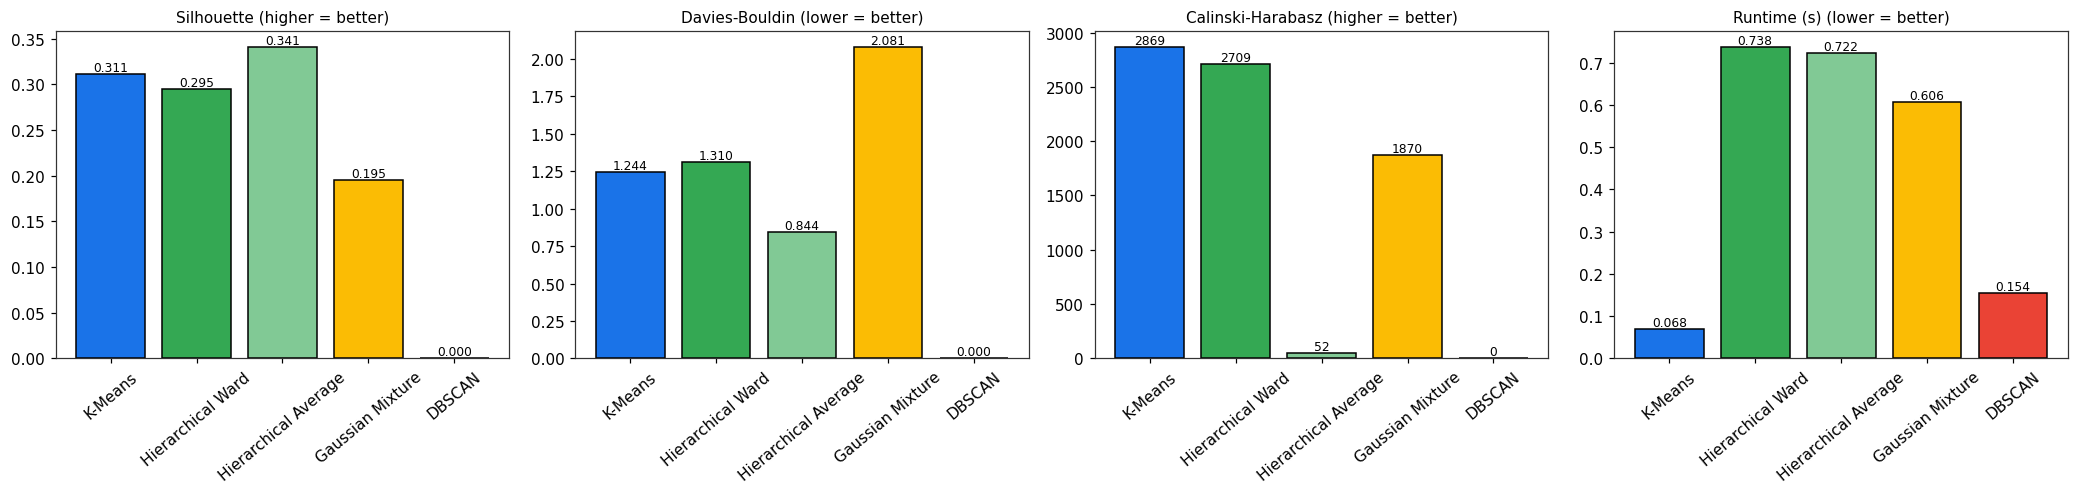

In [15]:
# Benchmark visualisation
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6))
names = bench_df.Algorithm.str.replace(r" \(.*\)", "", regex=True)
colors = ["#1a73e8", "#34a853", "#81c995", "#fbbc04", "#ea4335"]
for a, col, title, better in zip(ax, ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "Runtime_s"],
                                  ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "Runtime (s)"],
                                  ["higher", "lower", "higher", "lower"]):
    vals = bench_df[col].fillna(0)
    a.bar(names, vals, color=colors, edgecolor="black")
    a.set_title(f"{title} ({better} = better)", fontsize=10)
    a.tick_params(axis="x", rotation=40)
    for i, v in enumerate(vals):
        a.text(i, v, f"{v:.3f}" if col != "Calinski-Harabasz" else f"{v:.0f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig("outputs/fig5_3_algorithm_benchmark.png", dpi=300); plt.show()

## 7. Segment profiling & visualisation (K-Means, k = 4)

In [16]:
ext_rfm["Cluster"] = labels4
order = ext_rfm.groupby("Cluster")["Monetary"].mean().sort_values(ascending=False).index.tolist()
label_map = dict(zip(order, ["Champions (VIP Loyalists)", "Loyal & Promising Regulars",
                             "High-Potential / At-Risk Guests", "Hibernating / Lost Guests"]))
ext_rfm["Segment_Label"] = ext_rfm["Cluster"].map(label_map)

profiles = ext_rfm.groupby("Segment_Label").agg(
    Customers=("Recency", "count"),
    Share_Pct=("Recency", lambda x: round(len(x) / len(ext_rfm) * 100, 1)),
    Recency=("Recency", "mean"), Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean"),
    InterPurchase_Time=("InterPurchase_Time", "mean"), Basket_Depth=("Basket_Depth", "mean"),
).loc[list(label_map.values())].round(2)
profiles.to_csv("outputs/table_4_3_segment_profiles.csv")
profiles

,Customers,Share_Pct,Recency,Frequency,Monetary,InterPurchase_Time,Basket_Depth
Segment_Label,,,,,,,
Champions (VIP Loyalists),515,11.9,12.38,16.51,10253.30,32.55,184.04
Loyal & Promising Regulars,1180,27.2,33.21,4.66,1795.53,73.66,87.56
High-Potential / At-Risk Guests,1071,24.7,102.95,2.68,763.65,107.31,32.34
Hibernating / Lost Guests,1572,36.2,156.24,1.06,426.31,0.13,21.67


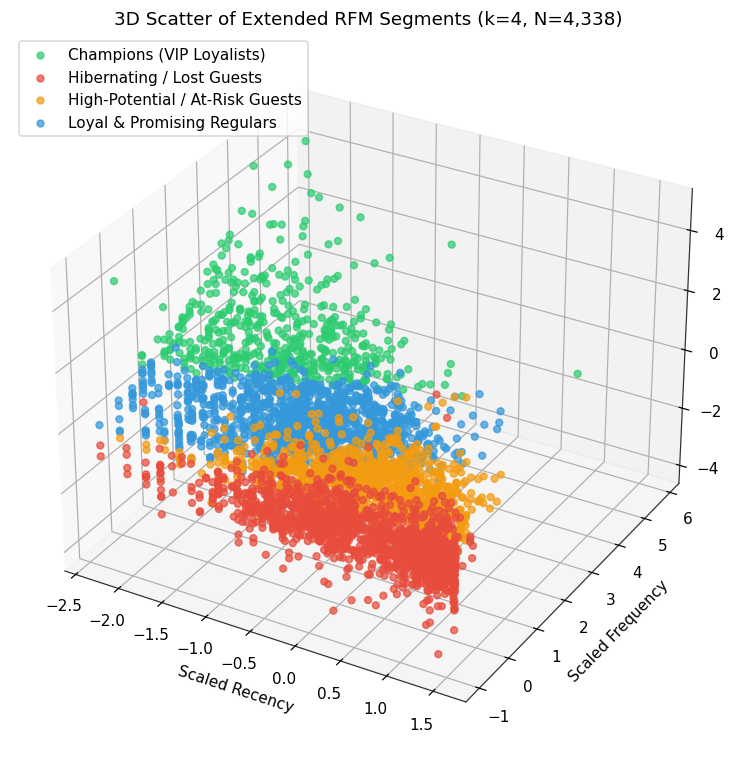

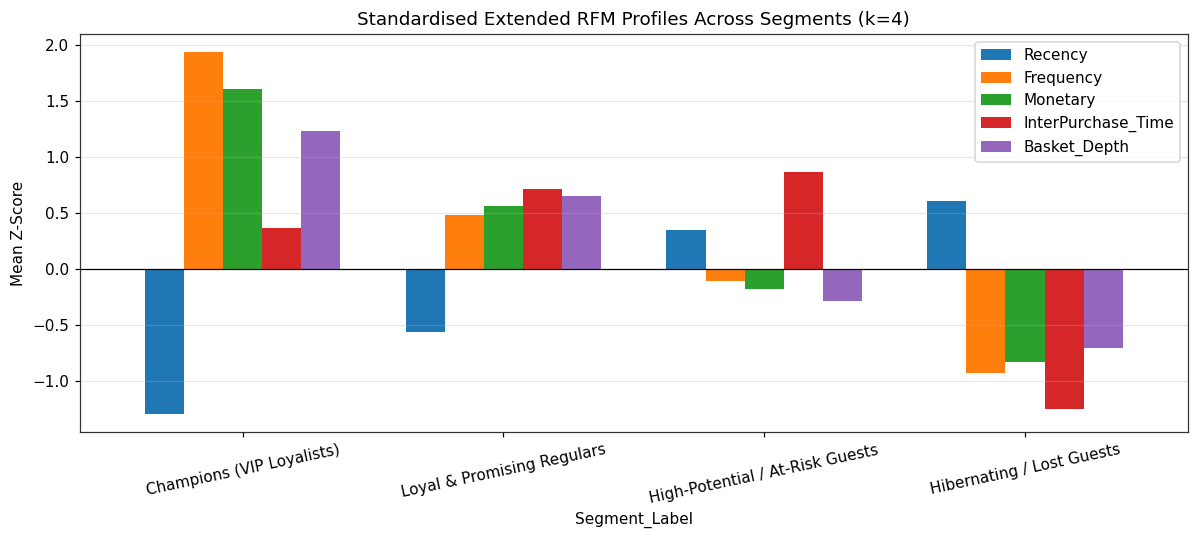

In [17]:
# Figure 4.5 - 3D scatter, Figure 4.6 - profile bars
palette = {"Champions (VIP Loyalists)": "#2ecc71", "Loyal & Promising Regulars": "#3498db",
           "High-Potential / At-Risk Guests": "#f39c12", "Hibernating / Lost Guests": "#e74c3c"}
fig = plt.figure(figsize=(10, 7)); ax = fig.add_subplot(111, projection="3d")
for seg, grp in ext_rfm.groupby("Segment_Label"):
    ax.scatter(rfm_scaled.loc[grp.index, "Recency"], rfm_scaled.loc[grp.index, "Frequency"],
               rfm_scaled.loc[grp.index, "Monetary"], label=seg, c=palette[seg], s=20, alpha=0.72)
ax.set_xlabel("Scaled Recency"); ax.set_ylabel("Scaled Frequency"); ax.set_zlabel("Scaled Monetary")
ax.set_title(f"3D Scatter of Extended RFM Segments (k=4, N={len(ext_rfm):,})"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("outputs/fig4_5_3d_clusters.png", dpi=300); plt.show()

scaled_means = rfm_scaled.groupby(ext_rfm["Segment_Label"])[feature_cols].mean().loc[list(label_map.values())]
scaled_means.plot(kind="bar", figsize=(11, 5), width=0.75, rot=12)
plt.axhline(0, color="black", lw=0.8); plt.ylabel("Mean Z-Score")
plt.title("Standardised Extended RFM Profiles Across Segments (k=4)"); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("outputs/fig4_6_segment_profiles.png", dpi=300); plt.show()

## 8. Automated marketing queue

In [18]:
q = ext_rfm.sort_index().copy()
q["Customer_Key"] = [f"ID-{int(i)}" for i in q.index]

def campaign(row):
    seg, cid, spend, depth = row["Segment_Label"], row["Customer_Key"], row["Monetary"], int(row["Basket_Depth"])
    if seg.startswith("Champions"):
        return pd.Series([f"Hi {cid}, thank you for spending ${spend:,.2f} across {depth} items! VIP early access unlocked.",
                          f"*WhatsApp VIP*: Hello {cid}, your priority loyalty tier reward is ready!"])
    if seg.startswith("Loyal"):
        return pd.Series([f"Hi {cid}, we curated new arrivals for your {depth}-item basket! Use code LOYAL15.",
                          f"*WhatsApp Exclusive*: Hi {cid}, claim 15% off your next bundle order!"])
    if seg.startswith("High-Potential"):
        return pd.Series([f"Hi {cid}, loved your recent order (${spend:,.2f})! Convert to VIP with code GUEST20.",
                          f"*WhatsApp Offer*: Hello {cid}, reorder today via WhatsApp & save 20%!"])
    return pd.Series([f"Hi {cid}, we miss you! Enjoy a 10% reactivation voucher: COMEBACK10.",
                      f"*WhatsApp Flash Sale*: Hi {cid}, tap here for clearance items!"])

q[["Email_Campaign", "WhatsApp_Campaign"]] = q.apply(campaign, axis=1)
queue = q[["Customer_Key", "Segment_Label", "Email_Campaign", "WhatsApp_Campaign"]]
queue.to_csv("outputs/final_marketing_queue_full.csv", index=False)
print(f"Queue rows: {len(queue):,}")
queue.groupby("Segment_Label", sort=False).head(2)

Queue rows: 4,338


,Customer_Key,Segment_Label,Email_Campaign,WhatsApp_Campaign
CustomerID,,,,
12346.0,ID-12346,Hibernating / Lost Guests,"Hi ID-12346, we miss you! Enjoy a 10% reactiva...","*WhatsApp Flash Sale*: Hi ID-12346, tap here f..."
12347.0,ID-12347,Champions (VIP Loyalists),"Hi ID-12347, thank you for spending $4,310.00 ...","*WhatsApp VIP*: Hello ID-12347, your priority ..."
12348.0,ID-12348,High-Potential / At-Risk Guests,"Hi ID-12348, loved your recent order ($1,797.2...","*WhatsApp Offer*: Hello ID-12348, reorder toda..."
12349.0,ID-12349,Hibernating / Lost Guests,"Hi ID-12349, we miss you! Enjoy a 10% reactiva...","*WhatsApp Flash Sale*: Hi ID-12349, tap here f..."
12352.0,ID-12352,Loyal & Promising Regulars,"Hi ID-12352, we curated new arrivals for your ...","*WhatsApp Exclusive*: Hi ID-12352, claim 15% o..."
12356.0,ID-12356,Loyal & Promising Regulars,"Hi ID-12356, we curated new arrivals for your ...","*WhatsApp Exclusive*: Hi ID-12356, claim 15% o..."
12362.0,ID-12362,Champions (VIP Loyalists),"Hi ID-12362, thank you for spending $5,226.23 ...","*WhatsApp VIP*: Hello ID-12362, your priority ..."
12363.0,ID-12363,High-Potential / At-Risk Guests,"Hi ID-12363, loved your recent order ($552.00)...","*WhatsApp Offer*: Hello ID-12363, reorder toda..."


## 9. Final evaluation summary

In [19]:
km_row = bench_df.iloc[0]
sil_k4 = eval_df.loc[eval_df.k == 4, "Silhouette"].iloc[0]
sil_k2 = eval_df.loc[eval_df.k == 2, "Silhouette"].iloc[0]
ari4 = stab_df.loc[stab_df.k == 4, "Mean_ARI"].iloc[0]
ari2 = stab_df.loc[stab_df.k == 2, "Mean_ARI"].iloc[0]
gap4 = gen_df.loc[gen_df.k == 4, "Gap"].iloc[0]
best = bench_df[bench_df.Valid_Segmentation].sort_values("Silhouette", ascending=False).iloc[0]["Algorithm"]

print("=" * 66)
print("MODEL EVALUATION SUMMARY")
print("=" * 66)
print(f"Selected model          : K-Means, k = 4  (N = {len(X):,}, 5 features)")
print(f"Silhouette  (k=4 / k=2) : {sil_k4:.4f} / {sil_k2:.4f}")
print(f"Davies-Bouldin (k=4)    : {km_row['Davies-Bouldin']:.4f}")
print(f"Calinski-Harabasz (k=4) : {km_row['Calinski-Harabasz']:.1f}")
print(f"Bootstrap ARI (k=4/k=2) : {ari4:.4f} / {ari2:.4f}")
print(f"Train-test silhouette gap (k=4): {gap4:+.4f}")
print(f"Best algorithm by silhouette (valid segmentations only): {best}")
print("\nInterpretation guide:")
print(" Silhouette  >0.5 strong | 0.25-0.5 reasonable structure | <0.25 weak")
print(" ARI         >0.8 very stable | 0.6-0.8 moderately stable | <0.6 unstable")
print(" Gap         near 0 = generalises to unseen customers")
print("\nNote: k=2 scores best on internal metrics; k=4 is chosen for business\n"
      "interpretability (four actionable marketing segments).")

MODEL EVALUATION SUMMARY
Selected model          : K-Means, k = 4  (N = 4,338, 5 features)
Silhouette  (k=4 / k=2) : 0.3113 / 0.4157
Davies-Bouldin (k=4)    : 1.2442
Calinski-Harabasz (k=4) : 2868.8
Bootstrap ARI (k=4/k=2) : 0.9371 / 0.9826
Train-test silhouette gap (k=4): -0.0040
Best algorithm by silhouette (valid segmentations only): K-Means (k=4)

Interpretation guide:
 Silhouette  >0.5 strong | 0.25-0.5 reasonable structure | <0.25 weak
 ARI         >0.8 very stable | 0.6-0.8 moderately stable | <0.6 unstable
 Gap         near 0 = generalises to unseen customers

Note: k=2 scores best on internal metrics; k=4 is chosen for business
interpretability (four actionable marketing segments).


In [20]:
# Colab: download everything (ignored outside Colab)
try:
    import shutil
    from google.colab import files
    shutil.make_archive("thesis_outputs", "zip", "outputs")
    files.download("thesis_outputs.zip")
except Exception:
    print("Not on Colab - results are in the ./outputs folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>